# LightGBM benchmark

This notebook evaluates LightGBM with grouped battery validation. The complete model comparison and final model selection are implemented in `src/train.py`.

## 1. Load data

In [1]:
from pathlib import Path
import pickle
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

root = Path.cwd().resolve()
if not (root / "Datasets").exists():
    root = root.parent

sys.path.insert(0, str(root / "src"))
from preprocess import FEATURE_COLUMNS, TARGET_COLUMN

master_path = root / "Datasets" / "Battery_RUL_Master.csv"
model_dir = root / "models"
report_dir = root / "reports"
model_dir.mkdir(exist_ok=True)
report_dir.mkdir(exist_ok=True)

battery_data = pd.read_csv(master_path)
features = ["Cycle_Index", *FEATURE_COLUMNS]
X = battery_data[features]
y = battery_data[TARGET_COLUMN]
battery_ids = battery_data["battery_id"]

print(f"Rows: {len(battery_data):,}")
print(f"Batteries: {battery_ids.nunique()}")
print(f"Features: {len(features)}")
X.head()

Rows: 15,064
Batteries: 14
Features: 8


,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s)
0,1.0,2595.30,1151.488500,3.670,3.211,5460.001,6755.01,10777.82
1,2.0,7408.64,1172.512500,4.246,3.220,5508.992,6762.02,10500.35
2,3.0,7393.76,1112.992000,4.249,3.224,5508.993,6762.02,10420.38
3,4.0,7385.50,1080.320667,4.250,3.225,5502.016,6762.02,10322.81
4,6.0,65022.75,29813.487000,4.290,3.398,5480.992,53213.54,56699.65


## Grouped validation

`battery_id` is used to keep complete batteries out of each validation fold.

In [2]:
params = {
    "n_estimators": 400,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "subsample": 0.85,
    "colsample_bytree": 0.9,
    "random_state": 42,
    "verbosity": -1,
}

cv = GroupKFold(n_splits=5)
oof_predictions = pd.Series(index=battery_data.index, dtype="float64")
fold_results = []

for fold, (train_index, valid_index) in enumerate(
    cv.split(X, y, groups=battery_ids), start=1
):
    train_batteries = set(battery_ids.iloc[train_index])
    valid_batteries = set(battery_ids.iloc[valid_index])
    assert train_batteries.isdisjoint(valid_batteries)

    model = LGBMRegressor(**params)
    model.fit(X.iloc[train_index], y.iloc[train_index])

    start_time = time.perf_counter()
    predictions = model.predict(X.iloc[valid_index])
    elapsed = time.perf_counter() - start_time
    oof_predictions.iloc[valid_index] = predictions

    fold_results.append(
        {
            "fold": fold,
            "validation_batteries": ", ".join(sorted(valid_batteries)),
            "mae": mean_absolute_error(y.iloc[valid_index], predictions),
            "rmse": mean_squared_error(y.iloc[valid_index], predictions, squared=False),
            "r2": r2_score(y.iloc[valid_index], predictions),
            "inference_ms_per_sample": elapsed * 1000 / len(valid_index),
        }
    )

fold_metrics = pd.DataFrame(fold_results)
fold_metrics

/home/jayanth/CODE/projects/Battery_RUL_Prediction/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


/home/jayanth/CODE/projects/Battery_RUL_Prediction/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


/home/jayanth/CODE/projects/Battery_RUL_Prediction/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


/home/jayanth/CODE/projects/Battery_RUL_Prediction/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


/home/jayanth/CODE/projects/Battery_RUL_Prediction/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


,fold,validation_batteries,mae,rmse,r2,inference_ms_per_sample
0,1,"HNEI_g, HNEI_o, HNEI_s",4.571456,6.328171,0.999614,0.004419
1,2,"HNEI_d, HNEI_e, HNEI_t",11.979586,15.883903,0.997607,0.004329
2,3,"HNEI_c, HNEI_j, HNEI_p",7.054066,8.666367,0.999273,0.005558
3,4,"HNEI_b, HNEI_n",5.113207,7.163405,0.999505,0.004396
4,5,"HNEI_a, HNEI_f, HNEI_l",5.365374,6.726383,0.999563,0.004495


## Metrics

In [3]:
metric_names = ["mae", "rmse", "r2", "inference_ms_per_sample"]
summary_metrics = pd.DataFrame(
    {
        "mean": fold_metrics[metric_names].mean(),
        "std": fold_metrics[metric_names].std(),
    }
).round(4)

summary_metrics

,mean,std
mae,6.8167,3.0315
rmse,8.9536,3.9740
r2,0.9991,0.0009
inference_ms_per_sample,0.0046,0.0005


## Actual vs predicted RUL

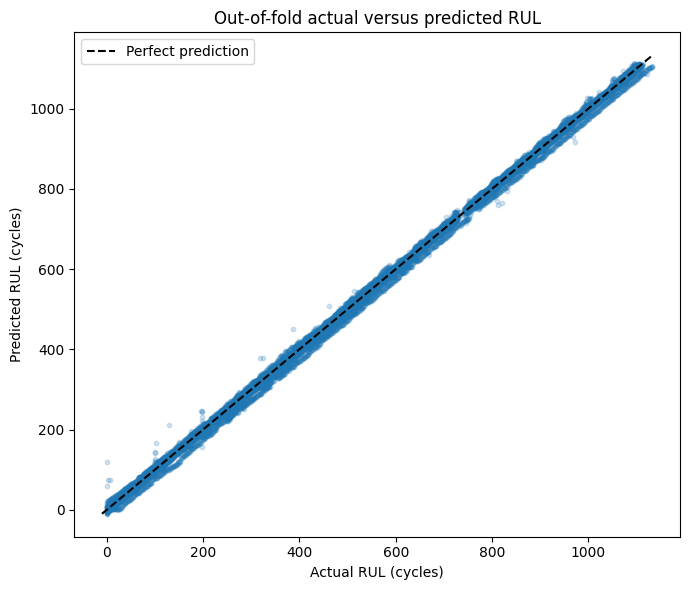

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y, oof_predictions, alpha=0.2, s=10)

limits = [min(y.min(), oof_predictions.min()), max(y.max(), oof_predictions.max())]
ax.plot(limits, limits, color="black", linestyle="--", label="Perfect prediction")
ax.set_title("Out-of-fold actual versus predicted RUL")
ax.set_xlabel("Actual RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.legend()
plt.tight_layout()

## Save the benchmark

In [5]:
final_model = LGBMRegressor(**params)
final_model.fit(X, y)

model_path = model_dir / "lightgbm_benchmark.pkl"
metrics_path = report_dir / "lightgbm_benchmark_metrics.csv"

with model_path.open("wb") as file:
    pickle.dump(final_model, file)

fold_metrics.to_csv(metrics_path, index=False)
print(f"Saved benchmark model to {model_path}")
print(f"Saved benchmark metrics to {metrics_path}")

Saved benchmark model to /home/jayanth/CODE/projects/Battery_RUL_Prediction/models/lightgbm_benchmark.pkl
Saved benchmark metrics to /home/jayanth/CODE/projects/Battery_RUL_Prediction/reports/lightgbm_benchmark_metrics.csv
